# Week 3 — MOFA+, XGBoost, Late Integration, SHAP, KEGG (Jaskirat)

Builds on the paired genera + metabolomics + metadata objects from Week 2 (Notebook 2 — Correlation Analysis). Run Week 2's data-loading cells first, or re-run Section 1 below, which reloads everything from scratch.

## 1. Load and align paired genera + metabolomics data

MOFA+ and late integration both require the **same samples** to be present in both omics blocks (unlike Notebooks 1/3/4, which only needed genera). We rebuild that paired set the same way Notebook 2 did.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

metadata = pd.read_csv("data/metadata.tsv", sep="\t")
genera = pd.read_csv("data/genera.tsv", sep="\t", index_col=0)
mtb = pd.read_csv("data/mtb.tsv", sep="\t", index_col=0)

metadata["Sample"] = metadata["Sample"].astype(str)
genera.index = genera.index.astype(str)
mtb.index = mtb.index.astype(str)

print("Metadata:", metadata.shape)
print("Genera:", genera.shape)
print("Metabolomics:", mtb.shape)

Metadata: (347, 15)
Genera: (347, 11942)
Metabolomics: (347, 450)


In [ ]:
# Keep only the later-stage comparison
keep_groups = ["Healthy", "Stage_III_IV"]

metadata_p = (
    metadata[metadata["Study.Group"].isin(keep_groups)]
    .copy()
    .set_index("Sample")
)

# Align both omics tables to the filtered metadata
genera_p = genera.loc[metadata_p.index].copy()
mtb_p = mtb.loc[metadata_p.index].copy()

# Binary label for later use in plots/tests
metadata_p["Binary.Group"] = (
    metadata_p["Study.Group"] == "Stage_III_IV"
).astype(int)

print("Metadata:", metadata_p.shape)
print("Genera:", genera_p.shape)
print("Metabolomics:", mtb_p.shape)

print("\nGroup counts:")
print(metadata_p["Study.Group"].value_counts())

print(
    "\nSame sample order:",
    genera_p.index.equals(mtb_p.index)
    and genera_p.index.equals(metadata_p.index)
)

Metadata: (181, 15)
Genera: (181, 11942)
Metabolomics: (181, 450)

Group counts:
Study.Group
Healthy         127
Stage_III_IV     54
Name: count, dtype: int64

Same sample order: True


In [ ]:
# --------------------------------------------------
# Genera preprocessing
# --------------------------------------------------

# Keep genera present in at least 10% of samples
genera_prevalence = (genera_p > 0).mean(axis=0)

genera_filt = genera_p.loc[
    :, genera_prevalence >= 0.10
].copy()

# Remove zero-variance genera
genera_filt = genera_filt.loc[
    :, genera_filt.std(axis=0) > 0
].copy()

# Log-transform relative abundances
genera_log = np.log1p(genera_filt * 1e6)

# Standardize
genera_z = (
    genera_log - genera_log.mean(axis=0)
) / genera_log.std(axis=0)

print("Original genera:", genera_p.shape)
print("Filtered genera:", genera_filt.shape)
print("Final genera matrix:", genera_z.shape)
print("Missing values:", genera_z.isna().sum().sum())

Original genera: (181, 11942)
Filtered genera: (181, 5230)
Final genera matrix: (181, 5230)
Missing values: 0


In [ ]:
# Mean relative abundance across samples
genera_mean = genera_p.mean(axis=0)

# Apply prevalence AND abundance filters
genera_filt = genera_p.loc[
    :,
    (genera_prevalence >= 0.10) &
    (genera_mean >= 1e-5)
].copy()

# Remove zero-variance features
genera_filt = genera_filt.loc[
    :, genera_filt.std(axis=0) > 0
].copy()

# Log transform
genera_log = np.log1p(genera_filt * 1e6)

# Standardize
genera_z = (
    genera_log - genera_log.mean(axis=0)
) / genera_log.std(axis=0)

print("Final genera matrix:", genera_z.shape)

Final genera matrix: (181, 723)


In [ ]:
# --------------------------------------------------
# Metabolomics preprocessing
# --------------------------------------------------

# Keep metabolites detected in at least 50% of samples
mtb_detection = (mtb_p > 0).mean(axis=0)

mtb_filt = mtb_p.loc[
    :,
    mtb_detection >= 0.50
].copy()

# Remove zero-variance metabolites
mtb_filt = mtb_filt.loc[
    :,
    mtb_filt.std(axis=0) > 0
].copy()

# Log transform
mtb_log = np.log1p(mtb_filt)

# Standardize
mtb_z = (
    mtb_log - mtb_log.mean(axis=0)
) / mtb_log.std(axis=0)

print("Final metabolite matrix:", mtb_z.shape)
print("Missing values:", mtb_z.isna().sum().sum())

Final metabolite matrix: (181, 163)
Missing values: 0


In [ ]:
# Install once (skip if already installed)
!pip install mofapy2 -q

In [ ]:


from mofapy2.run.entry_point import entry_point

def to_long(df, view_name):
    """
    Convert a feature matrix (samples × features)
    into MOFA long format.
    """
    long_df = (
        df.reset_index()
          .melt(
              id_vars=df.index.name or "index",
              var_name="feature",
              value_name="value"
          )
    )

    long_df = long_df.rename(
        columns={df.index.name or "index": "sample"}
    )

    long_df["view"] = view_name
    long_df["group"] = "group1"

    return long_df[
        ["sample", "group", "feature", "view", "value"]
    ]


long_genera = to_long(genera_z, "Genera")
long_mtb = to_long(mtb_z, "Metabolomics")

mofa_data = pd.concat(
    [long_genera, long_mtb],
    ignore_index=True
)

print(mofa_data.head())
print()
print(mofa_data["view"].value_counts())

  sample   group                                            feature    view  \
0  10023  group1  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...  Genera   
1  10025  group1  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...  Genera   
2  10029  group1  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...  Genera   
3  10031  group1  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...  Genera   
4  10036  group1  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...  Genera   

      value  
0 -0.097115  
1 -0.430829  
2 -0.282478  
3 -0.438114  
4 -0.733092  

view
Genera          130863
Metabolomics     29503
Name: count, dtype: int64


In [ ]:
from mofapy2.run.entry_point import entry_point

ent = entry_point()

# Data options
ent.set_data_options(
    scale_groups=False,
    scale_views=False
)

# Load data
ent.set_data_df(mofa_data)

# Model options
ent.set_model_options(
    factors=10,
    spikeslab_weights=True,
    ard_weights=True
)

# Training options
ent.set_train_options(
    iter=1000,
    convergence_mode="fast",
    seed=42
)

print("Building model...")
ent.build()

print("Training MOFA...")
ent.run()

print("Saving model...")
ent.save("mofa_model_late_stage.hdf5")

print("✓ MOFA training complete")


        #########################################################
        ###           __  __  ____  ______                    ### 
        ###          |  \/  |/ __ \|  ____/\    _             ### 
        ###          | \  / | |  | | |__ /  \ _| |_           ### 
        ###          | |\/| | |  | |  __/ /\ \_   _|          ###
        ###          | |  | | |__| | | / ____ \|_|            ###
        ###          |_|  |_|\____/|_|/_/    \_\              ###
        ###                                                   ### 
        ######################################################### 
         




Loaded group='group1' view='Genera' with N=181 samples and D=723 features...
Loaded group='group1' view='Metabolomics' with N=181 samples and D=163 features...


Model options:
- Automatic Relevance Determination prior on the factors: False
- Automatic Relevance Determination prior on the weights: True
- Spike-and-slab prior on the factors: False
- Spike-and-slab prior on the weights

In [ ]:
import h5py

with h5py.File("mofa_model_late_stage.hdf5", "r") as f:

    # Latent factors (samples × factors)
    Z = f["expectations"]["Z"]["group1"][()].T

    # Variance explained
    var_expl = f["variance_explained"]["r2_per_factor"]["group1"][()]

    sample_names = [
        s.decode()
        for s in f["samples"]["group1"][()]
    ]

    view_names = [
        v.decode()
        for v in f["views"]["views"][()]
    ]

df_factors = pd.DataFrame(
    Z,
    index=sample_names,
    columns=[f"Factor{i+1}" for i in range(Z.shape[1])]
)

var_df = pd.DataFrame(
    var_expl,
    index=view_names,
    columns=df_factors.columns
)

print(df_factors.head())
print()
print(var_df)

        Factor1   Factor2   Factor3   Factor4   Factor5   Factor6   Factor7  \
10023 -1.314417 -0.673131  1.374701  1.976976 -0.678562 -1.201905  0.274013   
10025  0.783891  0.098252  1.286066  1.207256 -0.842411 -1.340428  0.482659   
10029  1.719353 -0.633145 -0.084984  0.169663  0.470284  0.487512  0.035125   
10031 -0.732379 -0.847694  1.106549 -0.068854 -1.640253 -0.955076  0.499989   
10036 -1.205366 -0.449153  0.078196  1.597399  0.276566 -0.161771 -0.249917   

        Factor8   Factor9  Factor10  
10023  0.005799  0.006213 -0.938310  
10025 -0.232333  0.884652 -0.211149  
10029 -0.921056 -0.437380 -0.540923  
10031 -0.279597  1.480689  0.775345  
10036 -0.151175 -0.448226 -1.313583  

                Factor1    Factor2  Factor3   Factor4   Factor5   Factor6  \
Genera        20.321524   0.113516  0.58397  6.178527  4.691994  4.849830   
Metabolomics   6.496063  13.522496  9.69126  1.972742  1.223930  0.106831   

               Factor7   Factor8   Factor9  Factor10  
Genera   

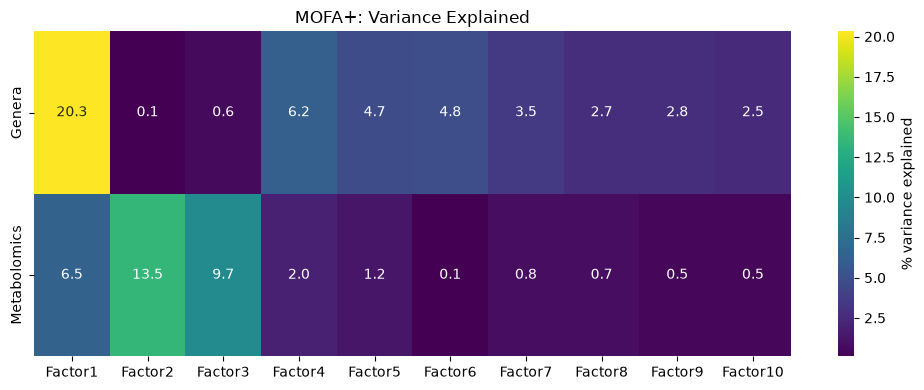

In [ ]:
plt.figure(figsize=(10,4))

sns.heatmap(
    var_df,
    annot=True,
    cmap="viridis",
    fmt=".1f",
    cbar_kws={"label":"% variance explained"}
)

plt.title("MOFA+: Variance Explained")
plt.tight_layout()
plt.show()

In [ ]:
df_plot = df_factors.copy()

df_plot["Study.Group"] = metadata_p.loc[
    df_plot.index,
    "Study.Group"
]

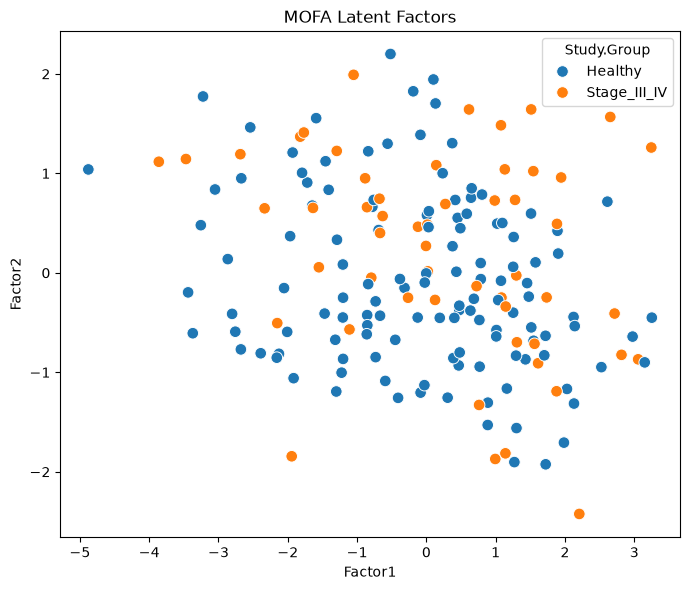

In [ ]:
plt.figure(figsize=(7,6))

sns.scatterplot(
    data=df_plot,
    x="Factor1",
    y="Factor2",
    hue="Study.Group",
    s=70
)

plt.title("MOFA Latent Factors")
plt.tight_layout()
plt.show()

In [ ]:
!pip install statsmodels -q


In [ ]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

results = []

for factor in df_factors.columns:

    healthy = df_plot.loc[
        df_plot["Study.Group"] == "Healthy",
        factor
    ]

    crc = df_plot.loc[
        df_plot["Study.Group"] == "Stage_III_IV",
        factor
    ]

    stat, p = mannwhitneyu(
        healthy,
        crc,
        alternative="two-sided"
    )

    results.append({
        "Factor": factor,
        "p_value": p
    })

results = pd.DataFrame(results)

results["FDR"] = multipletests(
    results["p_value"],
    method="fdr_bh"
)[1]

results = results.sort_values("FDR")

results

,Factor,p_value,FDR
4,Factor5,0.000075,0.000746
2,Factor3,0.000975,0.004876
9,Factor10,0.007215,0.024051
1,Factor2,0.012614,0.031534
6,Factor7,0.024875,0.049750
8,Factor9,0.082771,0.137952
0,Factor1,0.182946,0.261351
3,Factor4,0.321849,0.357610
7,Factor8,0.298212,0.357610
5,Factor6,0.736552,0.736552


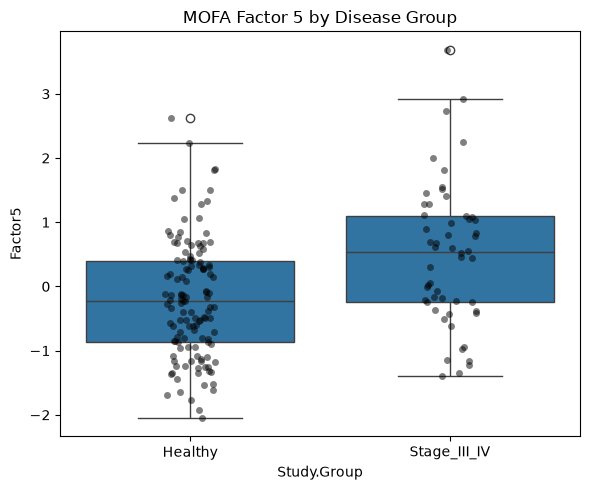

In [ ]:
plt.figure(figsize=(6,5))

sns.boxplot(
    data=df_plot,
    x="Study.Group",
    y="Factor5"
)

sns.stripplot(
    data=df_plot,
    x="Study.Group",
    y="Factor5",
    color="black",
    alpha=0.5
)

plt.title("MOFA Factor 5 by Disease Group")
plt.tight_layout()
plt.show()

extracting fetaure weights

In [ ]:
import h5py

with h5py.File("mofa_model_late_stage.hdf5", "r") as f:
    def print_structure(name, obj):
        print(name)

    f.visititems(print_structure)

data
data/Genera
data/Genera/group1
data/Metabolomics
data/Metabolomics/group1
expectations
expectations/W
expectations/W/Genera
expectations/W/Metabolomics
expectations/Z
expectations/Z/group1
features
features/Genera
features/Metabolomics
groups
groups/groups
intercepts
intercepts/Genera
intercepts/Genera/group1
intercepts/Metabolomics
intercepts/Metabolomics/group1
model_options
model_options/ard_factors
model_options/ard_weights
model_options/likelihoods
model_options/spikeslab_factors
model_options/spikeslab_weights
samples
samples/group1
training_opts
training_stats
training_stats/elbo
training_stats/number_factors
training_stats/time
variance_explained
variance_explained/r2_per_factor
variance_explained/r2_per_factor/group1
variance_explained/r2_total
variance_explained/r2_total/group1
views
views/views


In [ ]:
import h5py

with h5py.File("mofa_model_late_stage.hdf5", "r") as f:

    # Weight matrices
    W_genera = f["expectations"]["W"]["Genera"][()]
    W_mtb = f["expectations"]["W"]["Metabolomics"][()]

    # Feature names
    genera_names = [
        x.decode()
        for x in f["features"]["Genera"][()]
    ]

    mtb_names = [
        x.decode()
        for x in f["features"]["Metabolomics"][()]
    ]

print("Genera weights:", W_genera.shape)
print("Metabolite weights:", W_mtb.shape)

Genera weights: (10, 723)
Metabolite weights: (10, 163)


In [ ]:
# Factor 5 weights (row index 4)
factor5_weights = pd.DataFrame({
    "Genus": genera_names,
    "Weight": W_genera[4]
})

# Sort by absolute contribution
factor5_weights["AbsWeight"] = factor5_weights["Weight"].abs()

factor5_weights = factor5_weights.sort_values(
    "AbsWeight",
    ascending=False
)

factor5_weights.head(20)

,Genus,Weight,AbsWeight
324,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.599727,0.599727
135,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.559578,0.559578
611,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.536143,0.536143
452,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.514554,0.514554
220,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.497406,0.497406
508,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.494117,0.494117
284,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,-0.493905,0.493905
654,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.486841,0.486841
681,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,0.485343,0.485343
241,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,0.481896,0.481896


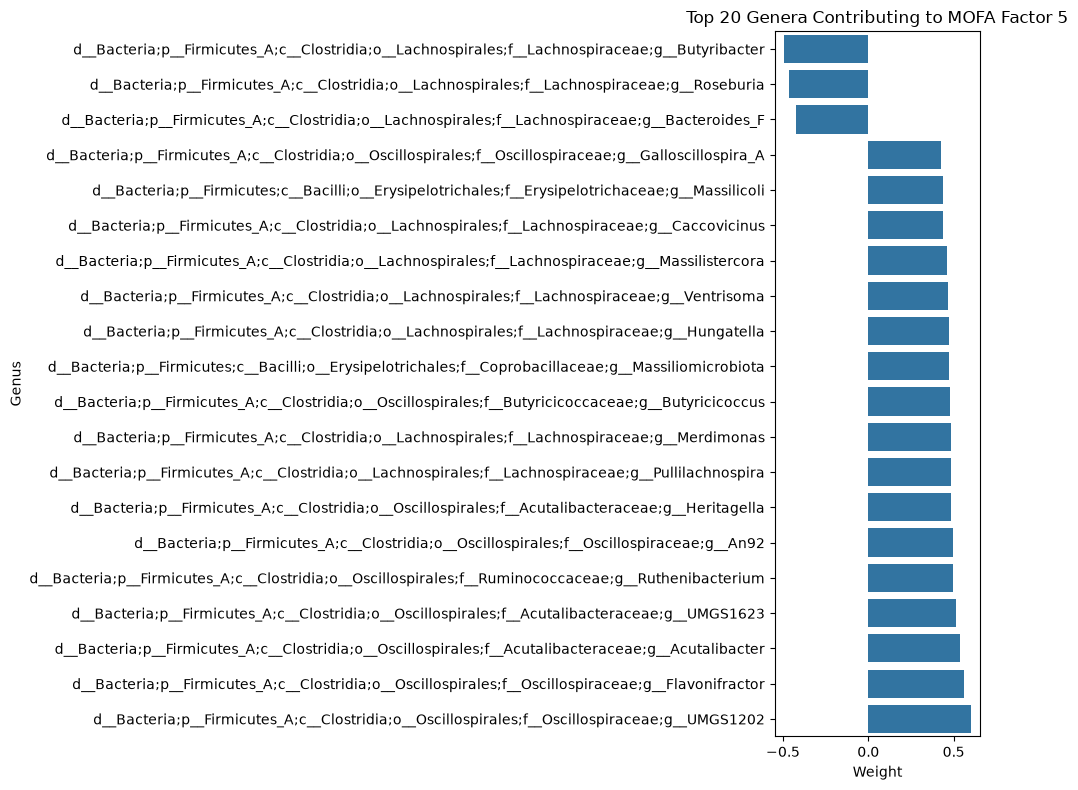

In [ ]:
top20 = factor5_weights.head(20).sort_values("Weight")

plt.figure(figsize=(10,8))

sns.barplot(
    data=top20,
    x="Weight",
    y="Genus"
)

plt.title("Top 20 Genera Contributing to MOFA Factor 5")
plt.tight_layout()
plt.show()

In [ ]:
# Keep only the genus name (everything after g__)
factor5_weights["Genus_short"] = (
    factor5_weights["Genus"]
    .str.extract(r"g__([^;]+)$")
)

In [ ]:
top_positive = (
    factor5_weights
    .sort_values("Weight", ascending=False)
    .head(10)
)

top_negative = (
    factor5_weights
    .sort_values("Weight")
    .head(10)
)

plot_df = pd.concat([top_negative, top_positive])

In [ ]:
factor3_weights = pd.DataFrame({
    "Metabolite": mtb_names,
    "Weight": W_mtb[2]
})

factor3_weights["AbsWeight"] = factor3_weights["Weight"].abs()

factor3_weights = factor3_weights.sort_values(
    "AbsWeight",
    ascending=False
)

factor3_weights.head(20)

,Metabolite,Weight,AbsWeight
114,C00019_SAM+,0.784418,0.784418
76,C00612_N1-Acetylspermidine,0.712879,0.712879
9,C00993_Ala-Ala,0.664796,0.664796
18,C00099_beta-Ala,0.658214,0.658214
75,"N1,N8-Diacetylspermidine",0.640938,0.640938
160,C00170_5-Methylthioadenosine,0.613112,0.613112
16,C00049_Asp,0.605290,0.605290
84,C02997_N-Acetylhistidine,0.592384,0.592384
74,"C03413_N1,N12-Diacetylspermine",0.581314,0.581314
90,C02727_N-epsilon-Acetyllysine,0.569019,0.569019


| Factor    | Genera (%) | Metabolites (%) |     FDR | Interpretation                          |
| --------- | ---------: | --------------: | ------: | --------------------------------------- |
| Factor 5  |        4.7 |             1.2 | 0.00075 | Disease-associated, microbiome-dominant |
| Factor 3  |        0.6 |             9.7 | 0.00488 | Disease-associated, metabolome-dominant |
| Factor 2  |        0.1 |            13.5 | 0.03153 | Metabolome-specific                     |
| Factor 10 |        2.5 |             0.5 | 0.02405 | Weak microbiome-driven                  |
| Factor 7  |        3.5 |             0.8 | 0.04975 | Borderline microbiome-driven            |


XGBOOST

In [ ]:
# Raw genus features for Healthy vs Stage III/IV
X_genus = genera_p.copy()

# Binary outcome: Healthy = 0, Stage III/IV = 1
y = metadata_p["Binary.Group"].copy()

print("X shape:", X_genus.shape)
print("\nClass counts:")
print(y.value_counts())

print(
    "\nSame sample order:",
    X_genus.index.equals(y.index)
)

print(
    "Any missing values:",
    X_genus.isna().sum().sum()
)

X shape: (181, 11942)

Class counts:
Binary.Group
0    127
1     54
Name: count, dtype: int64

Same sample order: True
Any missing values: 0


In [ ]:
# Install once if needed
!pip install xgboost -q

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

xgb_genus_pipe = Pipeline([
    # Learned separately inside each training fold
    ("variance_filter", VarianceThreshold(threshold=0.0)),

    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

print(xgb_genus_pipe)

Pipeline(steps=[('variance_filter', VarianceThreshold()),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.8, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
               

Genus XGBoost ROC-AUC: 0.849


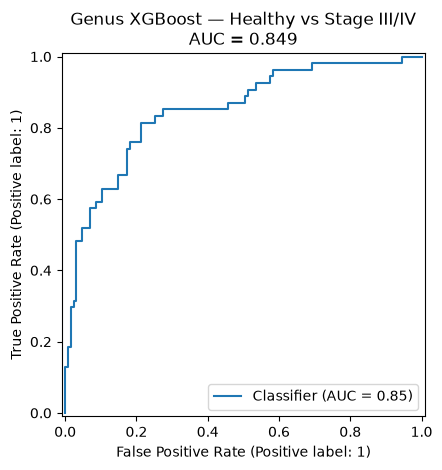

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score, RocCurveDisplay

y_genus_proba = cross_val_predict(
    xgb_genus_pipe,
    X_genus,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

auc_genus = roc_auc_score(y, y_genus_proba)

print("Genus XGBoost ROC-AUC:", round(auc_genus, 3))

RocCurveDisplay.from_predictions(
    y,
    y_genus_proba
)

plt.title(f"Genus XGBoost — Healthy vs Stage III/IV\nAUC = {auc_genus:.3f}")
plt.tight_layout()
plt.show()

In [ ]:
# Raw metabolomics matrix
X_mtb = mtb_p.copy()

print("Shape:", X_mtb.shape)
print("Missing values:", X_mtb.isna().sum().sum())

print(
    "Same sample order:",
    X_mtb.index.equals(y.index)
)

Shape: (181, 450)
Missing values: 0
Same sample order: True


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

xgb_mtb_pipe = Pipeline([
    ("variance_filter", VarianceThreshold()),

    ("model",
     XGBClassifier(
         n_estimators=300,
         max_depth=3,
         learning_rate=0.05,
         subsample=0.8,
         colsample_bytree=0.8,
         objective="binary:logistic",
         eval_metric="logloss",
         random_state=42,
         n_jobs=-1
     ))
])

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

Metabolomics XGBoost AUC: 0.736


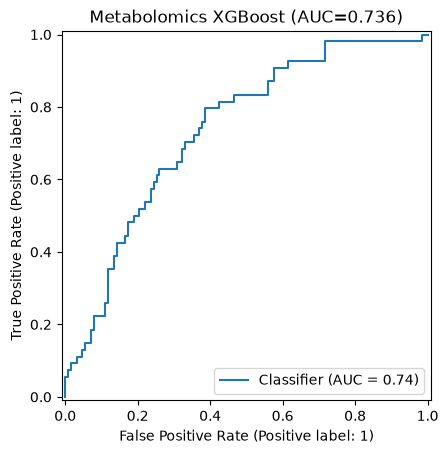

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score, RocCurveDisplay

y_mtb_proba = cross_val_predict(
    xgb_mtb_pipe,
    X_mtb,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:,1]

auc_mtb = roc_auc_score(
    y,
    y_mtb_proba
)

print("Metabolomics XGBoost AUC:",
      round(auc_mtb,3))

RocCurveDisplay.from_predictions(
    y,
    y_mtb_proba
)

plt.title(
    f"Metabolomics XGBoost (AUC={auc_mtb:.3f})"
)
plt.show()

Late Integration ROC-AUC: 0.842


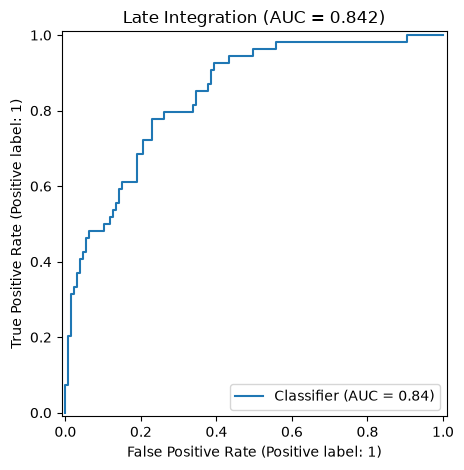

In [ ]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt

# Average probabilities
y_late_proba = (y_genus_proba + y_mtb_proba) / 2

auc_late = roc_auc_score(y, y_late_proba)

print("Late Integration ROC-AUC:", round(auc_late, 3))

RocCurveDisplay.from_predictions(
    y,
    y_late_proba
)

plt.title(f"Late Integration (AUC = {auc_late:.3f})")
plt.tight_layout()
plt.show()

Interpretation

The late integration model did not improve over the genus-only model.

That is a perfectly valid scientific result.

It suggests that, with simple probability averaging, the metabolomics model did not add enough complementary information to improve discrimination beyond what the microbiome already provided.

This is something you can discuss in your report rather than trying to "fix."

Why might this happen?

Several possibilities:

Genus features already capture most of the discriminative signal for Healthy vs Stage III/IV.
The metabolomics model is weaker (AUC = 0.736), so averaging its predictions with the stronger genus model slightly dilutes the signal.
Simple averaging is a very basic late-fusion strategy. More sophisticated approaches (e.g., weighted averaging or stacking) can sometimes improve performance, but they also add complexity and require careful validation.

"Late integration by averaging the prediction probabilities from genus and metabolomics XGBoost models did not outperform the genus-only model, indicating that the metabolomics data did not provide substantial additional predictive information for this classification task."

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from xgboost import XGBClassifier

xgb_genus_shap_pipe = Pipeline([
    ("variance_filter", VarianceThreshold(threshold=0.0)),

    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=2
    ))
])

In [ ]:
xgb_genus_shap_pipe.fit(X_genus, y)

print("Final interpretation model fitted.")

Final interpretation model fitted.


In [ ]:
fitted_filter = xgb_genus_shap_pipe.named_steps["variance_filter"]
fitted_model = xgb_genus_shap_pipe.named_steps["model"]

retained_mask = fitted_filter.get_support()
retained_genera = X_genus.columns[retained_mask]

X_genus_shap = pd.DataFrame(
    fitted_filter.transform(X_genus),
    index=X_genus.index,
    columns=retained_genera
)

print("Original features:", X_genus.shape[1])
print("Retained features:", X_genus_shap.shape[1])

Original features: 11942
Retained features: 11280


In [ ]:
print(genera_filt.shape)

(181, 723)


In [ ]:
from xgboost import XGBClassifier

xgb_shap = XGBClassifier(

    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,

    subsample=0.8,
    colsample_bytree=0.8,

    objective="binary:logistic",
    eval_metric="logloss",

    random_state=42,

    tree_method="hist",

    n_jobs=2

)

xgb_shap.fit(
    genera_filt,
    y
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
import shap

explainer = shap.TreeExplainer(
    xgb_shap
)

shap_values = explainer.shap_values(
    genera_filt
)

/data/scratch/sohaj01/crc_project/crc_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/data/scratch/sohaj01/crc_project/crc_env/lib/python3.13/site-packages/shap/plots/_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


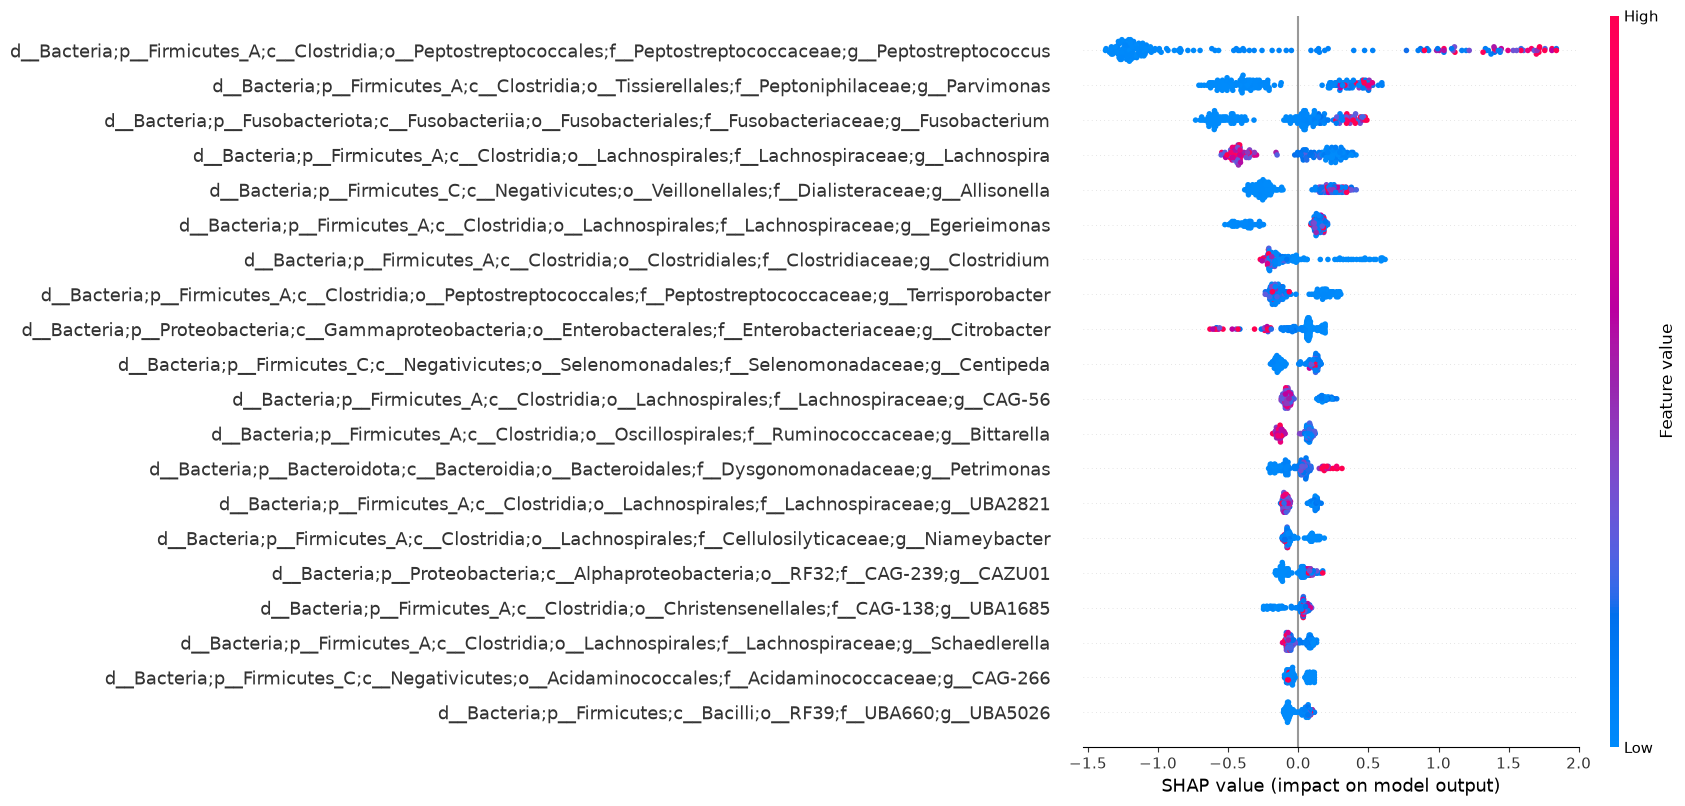

In [ ]:
shap.summary_plot(
    shap_values,
    genera_filt
)

/data/scratch/sohaj01/crc_project/crc_env/lib/python3.13/site-packages/shap/plots/_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


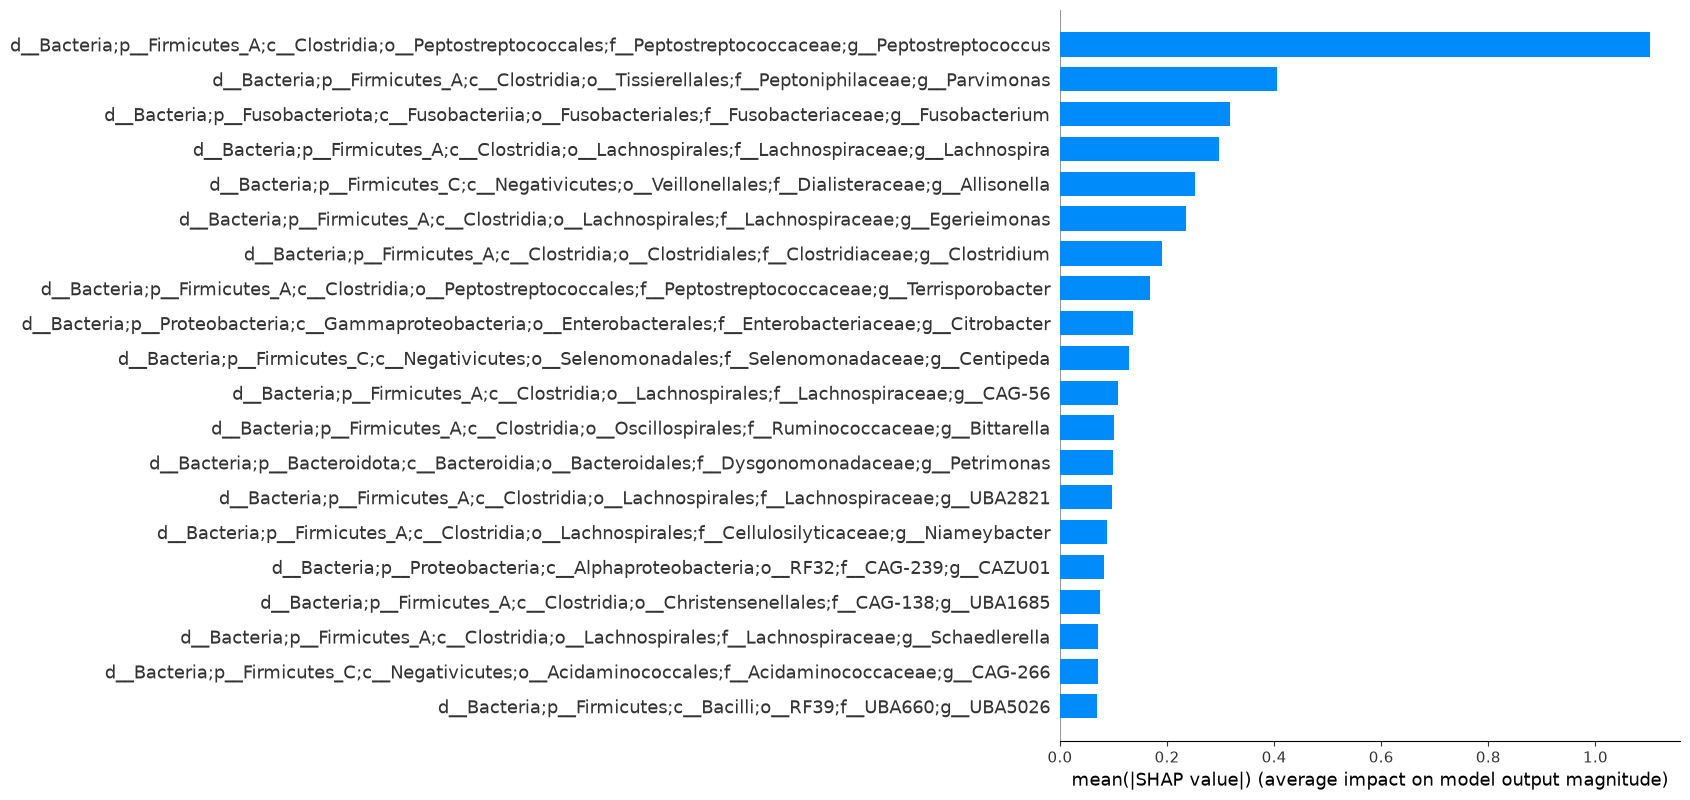

In [ ]:
shap.summary_plot(
    shap_values,
    genera_filt,
    plot_type="bar"
)

In [ ]:
import h5py
import pandas as pd

with h5py.File("mofa_model_late_stage.hdf5", "r") as f:

    # Genera feature names
    genera_names = [
        x.decode() if isinstance(x, bytes) else x
        for x in f["features"]["Genera"][()]
    ]

    # Factor weights (Factors × Features)
    W = f["expectations"]["W"]["Genera"][()]

genera_weights = pd.DataFrame(
    W,
    index=[f"Factor{i+1}" for i in range(W.shape[0])],
    columns=genera_names
)

print(genera_weights.shape)

(10, 723)


In [ ]:
# Factor 5 (remember Python starts at 0)
factor5 = genera_weights.iloc[4]

print(factor5.head())

d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__CAG-272;g__Flemingibacterium            -0.122661
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__F0428                 -0.106037
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Lachnoanaerobaculum   -0.006719
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__GCA-900066755          0.211440
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Monoglobales;f__Monoglobaceae;g__Monoglobus                -0.052485
Name: Factor5, dtype: float64


In [ ]:
top_positive = factor5.sort_values(ascending=False).head(20)

print(top_positive)

d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__UMGS1202              0.599727
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__Flavonifractor        0.559578
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Acutalibacter       0.536143
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__UMGS1623            0.514554
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae;g__Ruthenibacterium       0.497406
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__An92                  0.494117
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Heritagella         0.486841
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Pullilachnospira        0.485343
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g

In [ ]:
top_negative = factor5.sort_values().head(20)

print(top_negative)

d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Butyribacter     -0.493905
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Roseburia        -0.463597
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Bacteroides_F    -0.426096
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__CAG-632          -0.424731
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Falcatimonas     -0.421371
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__CAG-411          -0.410124
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__1XD42-69         -0.398677
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Lachnospira      -0.396382
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__CAG-603          -0.389809
d__Bacteria;p__Firm

In [ ]:
import numpy as np
import pandas as pd

shap_importance = pd.DataFrame({
    "Genus": genera_filt.columns,
    "MeanSHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values("MeanSHAP", ascending=False)
    .reset_index(drop=True)
)

# Add SHAP rank
shap_importance["SHAP_Rank"] = np.arange(1, len(shap_importance)+1)

shap_importance.head(20)

,Genus,MeanSHAP,SHAP_Rank
0,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__P...,1.102782,1
1,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__T...,0.406097,2
2,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia...,0.317632,3
3,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,0.296765,4
4,d__Bacteria;p__Firmicutes_C;c__Negativicutes;o...,0.252190,5
5,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,0.234566,6
6,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__C...,0.190943,7
7,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__P...,0.168225,8
8,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,0.136134,9
9,d__Bacteria;p__Firmicutes_C;c__Negativicutes;o...,0.129194,10


In [ ]:
factor5_df = pd.DataFrame({
    "Genus": genera_weights.columns,
    "Factor5Weight": genera_weights.loc["Factor5"].values
})

factor5_df["AbsWeight"] = factor5_df["Factor5Weight"].abs()

factor5_df = (
    factor5_df
    .sort_values("AbsWeight", ascending=False)
    .reset_index(drop=True)
)

factor5_df["MOFA_Rank"] = np.arange(1, len(factor5_df)+1)

factor5_df.head(20)

,Genus,Factor5Weight,AbsWeight,MOFA_Rank
0,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.599727,0.599727,1
1,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.559578,0.559578,2
2,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.536143,0.536143,3
3,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.514554,0.514554,4
4,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.497406,0.497406,5
5,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.494117,0.494117,6
6,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,-0.493905,0.493905,7
7,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.486841,0.486841,8
8,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,0.485343,0.485343,9
9,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,0.481896,0.481896,10


In [ ]:
comparison = pd.merge(
    shap_importance,
    factor5_df,
    on="Genus",
    how="inner"
)

comparison = comparison.sort_values("SHAP_Rank")

comparison.head(30)

,Genus,MeanSHAP,SHAP_Rank,Factor5Weight,AbsWeight,MOFA_Rank
0,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__P...,1.102782,1,0.214498,0.214498,187
1,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__T...,0.406097,2,0.219406,0.219406,177
2,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia...,0.317632,3,0.109956,0.109956,350
3,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,0.296765,4,-0.396382,0.396382,35
4,d__Bacteria;p__Firmicutes_C;c__Negativicutes;o...,0.252190,5,-0.014298,0.014298,624
5,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,0.234566,6,0.266645,0.266645,127
6,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__C...,0.190943,7,-0.129394,0.129394,314
7,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__P...,0.168225,8,-0.247746,0.247746,146
8,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,0.136134,9,-0.084779,0.084779,394
9,d__Bacteria;p__Firmicutes_C;c__Negativicutes;o...,0.129194,10,0.026903,0.026903,559


In [ ]:
top_shap = set(
    shap_importance.head(20)["Genus"]
)

top_mofa = set(
    factor5_df.head(20)["Genus"]
)

shared = top_shap.intersection(top_mofa)

print(f"Shared genera: {len(shared)}\n")

for g in sorted(shared):
    print(g)

Shared genera: 0



In [ ]:
import re

def extract_genus_name(taxonomy):
    taxonomy = str(taxonomy)

    match = re.search(r"g__([^;]+)", taxonomy)

    if match:
        return match.group(1)

    return taxonomy


shap_importance["Genus_short"] = (
    shap_importance["Genus"]
    .apply(extract_genus_name)
)

factor5_df["Genus_short"] = (
    factor5_df["Genus"]
    .apply(extract_genus_name)
)

In [ ]:
print(
    shap_importance[
        ["Genus", "Genus_short"]
    ].head()
)

print(
    factor5_df[
        ["Genus", "Genus_short"]
    ].head()
)

                                               Genus         Genus_short
0  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__P...  Peptostreptococcus
1  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__T...          Parvimonas
2  d__Bacteria;p__Fusobacteriota;c__Fusobacteriia...       Fusobacterium
3  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...         Lachnospira
4  d__Bacteria;p__Firmicutes_C;c__Negativicutes;o...         Allisonella
                                               Genus       Genus_short
0  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...          UMGS1202
1  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...    Flavonifractor
2  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...     Acutalibacter
3  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...          UMGS1623
4  d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...  Ruthenibacterium


In [ ]:
comparison_short = pd.merge(
    shap_importance,
    factor5_df,
    on="Genus_short",
    how="inner",
    suffixes=("_SHAP", "_MOFA")
)

comparison_short = (
    comparison_short
    .sort_values("SHAP_Rank")
)

print(
    comparison_short[
        [
            "Genus_short",
            "SHAP_Rank",
            "MeanSHAP",
            "MOFA_Rank",
            "Factor5Weight"
        ]
    ].head(30)
)

           Genus_short  SHAP_Rank  MeanSHAP  MOFA_Rank  Factor5Weight
0   Peptostreptococcus          1  1.102782        187       0.214498
1           Parvimonas          2  0.406097        177       0.219406
2        Fusobacterium          3  0.317632        350       0.109956
3          Lachnospira          4  0.296765         35      -0.396382
4          Allisonella          5  0.252190        624      -0.014298
5         Egerieimonas          6  0.234566        127       0.266645
6          Clostridium          7  0.190943        314      -0.129394
7     Terrisporobacter          8  0.168225        146      -0.247746
8          Citrobacter          9  0.136134        394      -0.084779
9            Centipeda         10  0.129194        559       0.026903
10              CAG-56         11  0.107962        375       0.096990
11          Bittarella         12  0.101533        173       0.223705
12          Petrimonas         13  0.098963        467       0.053967
13             UBA28

In [ ]:
top_shap_short = set(
    shap_importance
    .head(20)["Genus_short"]
)

top_mofa_short = set(
    factor5_df
    .head(20)["Genus_short"]
)

shared_short = (
    top_shap_short
    .intersection(top_mofa_short)
)

print("Shared cleaned genera:", len(shared_short))

for genus in sorted(shared_short):
    print(genus)

Shared cleaned genera: 0


In [ ]:
shap_top20_with_mofa = pd.merge(
    shap_importance.head(20),
    factor5_df[
        [
            "Genus_short",
            "Factor5Weight",
            "AbsWeight",
            "MOFA_Rank"
        ]
    ],
    on="Genus_short",
    how="left"
)

print(
    shap_top20_with_mofa[
        [
            "Genus_short",
            "SHAP_Rank",
            "MeanSHAP",
            "Factor5Weight",
            "MOFA_Rank"
        ]
    ]
)

           Genus_short  SHAP_Rank  MeanSHAP  Factor5Weight  MOFA_Rank
0   Peptostreptococcus          1  1.102782       0.214498        187
1           Parvimonas          2  0.406097       0.219406        177
2        Fusobacterium          3  0.317632       0.109956        350
3          Lachnospira          4  0.296765      -0.396382         35
4          Allisonella          5  0.252190      -0.014298        624
5         Egerieimonas          6  0.234566       0.266645        127
6          Clostridium          7  0.190943      -0.129394        314
7     Terrisporobacter          8  0.168225      -0.247746        146
8          Citrobacter          9  0.136134      -0.084779        394
9            Centipeda         10  0.129194       0.026903        559
10              CAG-56         11  0.107962       0.096990        375
11          Bittarella         12  0.101533       0.223705        173
12          Petrimonas         13  0.098963       0.053967        467
13             UBA28

In [ ]:

factor_names = genera_weights.index.tolist()

dominant_factor = []

for genus in genera_weights.columns:

    weights = genera_weights[genus]

    idx = np.argmax(np.abs(weights))

    dominant_factor.append({
        "Genus_short": genus.split("g__")[-1] if "g__" in genus else genus,
        "DominantFactor": factor_names[idx],
        "Loading": weights.iloc[idx],
        "AbsLoading": abs(weights.iloc[idx])
    })

dominant_factor = pd.DataFrame(dominant_factor)

dominant_factor.head()

,Genus_short,DominantFactor,Loading,AbsLoading
0,Flemingibacterium,Factor1,0.403747,0.403747
1,F0428,Factor10,0.324841,0.324841
2,Lachnoanaerobaculum,Factor10,0.636829,0.636829
3,GCA-900066755,Factor1,0.371304,0.371304
4,Monoglobus,Factor1,0.332280,0.332280


In [ ]:
comparison = pd.merge(
    shap_importance,
    dominant_factor,
    on="Genus_short",
    how="left"
)

comparison = comparison.sort_values("SHAP_Rank")

comparison[
    [
        "Genus_short",
        "SHAP_Rank",
        "MeanSHAP",
        "DominantFactor",
        "Loading",
        "AbsLoading"
    ]
].head(20)

,Genus_short,SHAP_Rank,MeanSHAP,DominantFactor,Loading,AbsLoading
0,Peptostreptococcus,1,1.102782,Factor10,0.540804,0.540804
1,Parvimonas,2,0.406097,Factor10,0.510671,0.510671
2,Fusobacterium,3,0.317632,Factor10,0.648565,0.648565
3,Lachnospira,4,0.296765,Factor5,-0.396382,0.396382
4,Allisonella,5,0.252190,Factor9,0.316133,0.316133
5,Egerieimonas,6,0.234566,Factor4,0.403513,0.403513
6,Clostridium,7,0.190943,Factor4,0.294006,0.294006
7,Terrisporobacter,8,0.168225,Factor10,0.256623,0.256623
8,Citrobacter,9,0.136134,Factor6,0.600840,0.600840
9,Centipeda,10,0.129194,Factor10,0.653228,0.653228


Count how many SHAP-important genera belong to each MOFA factor.

In [ ]:
factor_summary = (
    comparison.head(30)
    .groupby("DominantFactor")
    .size()
    .sort_values(ascending=False)
)

print(factor_summary)

DominantFactor
Factor4     9
Factor10    6
Factor1     4
Factor5     3
Factor8     3
Factor7     2
Factor9     2
Factor6     1
dtype: int64


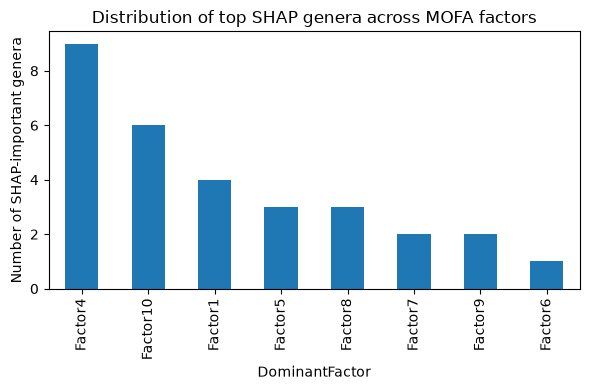

In [ ]:
import matplotlib.pyplot as plt

factor_summary.plot.bar(figsize=(6,4))

plt.ylabel("Number of SHAP-important genera")
plt.title("Distribution of top SHAP genera across MOFA factors")

plt.tight_layout()
plt.show()

Among the top 30 genera identified by the original genus XGBoost SHAP analysis, 9 have their strongest MOFA loading in Factor 4.

In [ ]:
weighted_summary = (
    comparison.head(30)
    .groupby("DominantFactor")["MeanSHAP"]
    .sum()
    .sort_values(ascending=False)
)

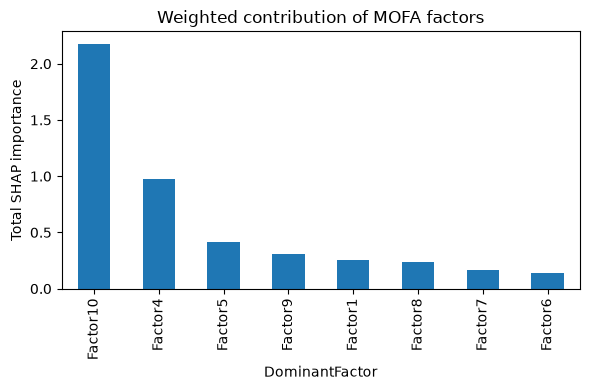

In [ ]:
weighted_summary.plot.bar(figsize=(6,4))
plt.ylabel("Total SHAP importance")
plt.title("Weighted contribution of MOFA factors")
plt.tight_layout()
plt.show()

In [ ]:
import h5py
import pandas as pd
import numpy as np

model_path = "mofa_model_late_stage.hdf5"

with h5py.File(model_path, "r") as f:
    W_mtb = f["expectations"]["W"]["Metabolomics"][()]

    mtb_names = [
        x.decode() if isinstance(x, bytes) else str(x)
        for x in f["features"]["Metabolomics"][()]
    ]

    print("Metabolite weight matrix:", W_mtb.shape)

Metabolite weight matrix: (10, 163)


In [ ]:

mtb_map = pd.read_csv(
    "data/mtb.map.tsv",
    sep="\t"
)

print(mtb_map.shape)
print(mtb_map.columns.tolist())

mtb_map.head()

(450, 4)
['Compound', 'KEGG', 'HMDB', 'High.Confidence.Annotation']


,Compound,KEGG,HMDB,High.Confidence.Annotation
0,C03173_(Methylthio)acetate,C03173,HMDB0035646,True
1,C03969_1-Amino-1-cyclopentanecarboxylate,C03969,HMDB0062225,True
2,C01234_1-Aminocyclopropane-1-carboxylate,C01234,HMDB0036458,True
3,C11118_1-Methyl-2-pyrrolidinone,C11118,HMDB0002039,True
4,C02494_1-Methyladenosine,C02494,HMDB0003331,True


In [ ]:
factor3_mtb = pd.DataFrame({
    "Compound": mtb_names,
    "Weight": W_mtb[2, :]   # Factor 3 = row index 2
})

factor3_mtb["AbsWeight"] = factor3_mtb["Weight"].abs()

factor3_mtb = factor3_mtb.sort_values(
    "AbsWeight",
    ascending=False
).reset_index(drop=True)

factor3_mtb.head(30)

,Compound,Weight,AbsWeight
0,C00019_SAM+,0.784418,0.784418
1,C00612_N1-Acetylspermidine,0.712879,0.712879
2,C00993_Ala-Ala,0.664796,0.664796
3,C00099_beta-Ala,0.658214,0.658214
4,"N1,N8-Diacetylspermidine",0.640938,0.640938
5,C00170_5-Methylthioadenosine,0.613112,0.613112
6,C00049_Asp,0.605290,0.605290
7,C02997_N-Acetylhistidine,0.592384,0.592384
8,"C03413_N1,N12-Diacetylspermine",0.581314,0.581314
9,C02727_N-epsilon-Acetyllysine,0.569019,0.569019


In [ ]:

mtb_map = pd.read_csv(
    "data/mtb.map.tsv",
    sep="\t"
)

print(mtb_map.shape)
print(mtb_map.columns.tolist())

mtb_map.head()

(450, 4)
['Compound', 'KEGG', 'HMDB', 'High.Confidence.Annotation']


,Compound,KEGG,HMDB,High.Confidence.Annotation
0,C03173_(Methylthio)acetate,C03173,HMDB0035646,True
1,C03969_1-Amino-1-cyclopentanecarboxylate,C03969,HMDB0062225,True
2,C01234_1-Aminocyclopropane-1-carboxylate,C01234,HMDB0036458,True
3,C11118_1-Methyl-2-pyrrolidinone,C11118,HMDB0002039,True
4,C02494_1-Methyladenosine,C02494,HMDB0003331,True


In [ ]:
factor3_annotated = factor3_mtb.merge(
    mtb_map,
    on="Compound",
    how="left"
)

print(
    factor3_annotated[
        [
            "Compound",
            "Weight",
            "KEGG",
            "High.Confidence.Annotation"
        ]
    ].head(30)
)

print(
    "\nTop 30 with KEGG IDs:",
    factor3_annotated.head(30)["KEGG"].notna().sum()
)

                                     Compound    Weight    KEGG  \
0                                 C00019_SAM+  0.784418  C00019   
1                  C00612_N1-Acetylspermidine  0.712879  C00612   
2                              C00993_Ala-Ala  0.664796  C00993   
3                             C00099_beta-Ala  0.658214  C00099   
4                    N1,N8-Diacetylspermidine  0.640938     NaN   
5                C00170_5-Methylthioadenosine  0.613112  C00170   
6                                  C00049_Asp  0.605290  C00049   
7                    C02997_N-Acetylhistidine  0.592384  C02997   
8              C03413_N1,N12-Diacetylspermine  0.581314  C03413   
9               C02727_N-epsilon-Acetyllysine  0.569019  C02727   
10                 C01029_N8-Acetylspermidine  0.554699  C01029   
11                                C00334_GABA  0.554304  C00334   
12                      C01015_Hydroxyproline  0.539105  C01015   
13                          C00024_Acetyl CoA  0.530449  C0002

In [ ]:
factor3_annotated.head(30).loc[
    factor3_annotated.head(30)["KEGG"].isna(),
    ["Compound", "Weight"]
]

,Compound,Weight
4,"N1,N8-Diacetylspermidine",0.640938


In [ ]:
pip install gseapy bioservices

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 663.7/663.7 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 718.5/718.5 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 50.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 616.8/616.8 kB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31/31 [bioservices] [bioservices]he]zer]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Top 30 metabolites
top30 = factor3_annotated.head(30)

# Remove metabolites without KEGG IDs
kegg_ids = (
    top30["KEGG"]
    .dropna()
    .tolist()
)

print(kegg_ids)
print(len(kegg_ids))

['C00019', 'C00612', 'C00993', 'C00099', 'C00170', 'C00049', 'C02997', 'C03413', 'C02727', 'C01029', 'C00334', 'C01015', 'C00024', 'C01181', 'C00020', 'C00105', 'C00263', 'C00956', 'C05771', 'C00003', 'C00630', 'C00008', 'C00386', 'C00043', 'C05127', 'C16741', 'C03626', 'C00647', 'C05135']
29


In [ ]:
import pandas as pd

kegg_df = pd.DataFrame({
    "KEGG_ID": kegg_ids
})

kegg_df.to_csv(
    "Factor3_KEGG_metabolites.csv",
    index=False
)

print(kegg_df.head())

  KEGG_ID
0  C00019
1  C00612
2  C00993
3  C00099
4  C00170


In [ ]:
import os

print(os.getcwd())

/data/scratch/sohaj01/crc_project
